<a href="https://colab.research.google.com/github/Stephin004/EduConnect/blob/main/Seaborn_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load Customers Dataset

customers = pd.read_csv("customers.csv")

customers.head()


,Customer_ID,Customer_Name,Age,Gender,City,Membership
0,1001,Arun,47.0,Male,Kochi,Regular
1,1002,Meera,33.0,Female,Thrissur,Regular
2,1003,Rahul,26.0,Male,Kochi,Silver
3,1004,Anjali,39.0,Female,Kottayam,Regular
4,1005,Vivek,37.0,Male,Thrissur,Silver


PART A — UNDERSTAND THE DATA

In [ ]:
# Load Products Dataset

products = pd.read_csv("products.csv")

products.head()


,Product_ID,Product,Category,Price
0,P01,Laptop,Electronics,65000
1,P02,Smartphone,Electronics,32000
2,P03,Headphones,Audio,3500
3,P04,Keyboard,Accessories,1800
4,P05,Mouse,Accessories,900


In [ ]:


# Load Orders Dataset

orders = pd.read_csv("orders.csv")

orders.head()


,Order_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Percent,Delivery_Days,Rating,Status,Payment_Method
0,5001,1012,P05,2026-01-01,1,5.0,2,NaN,Cancelled,UPI
1,5002,1039,P12,2026-01-02,1,0.0,4,3.0,Delivered,UPI
2,5003,1002,P03,2026-01-04,1,15.0,2,4.0,Delivered,Net Banking
3,5004,1003,P04,2026-01-05,1,15.0,2,4.0,Delivered,Card
4,5005,1037,P03,2026-01-07,4,25.0,3,5.0,Delivered,Card


In [ ]:
# 2. Identify the number of records and columns in each dataset.
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)

print("\nCustomers - Records:", customers.shape[0])
print("Customers - Columns:", customers.shape[1])

print("\nProducts - Records:", products.shape[0])
print("Products - Columns:", products.shape[1])

print("\nOrders - Records:", orders.shape[0])
print("Orders - Columns:", orders.shape[1])

Customers: (40, 6)
Products: (12, 4)
Orders: (120, 10)

Customers - Records: 40
Customers - Columns: 6

Products - Records: 12
Products - Columns: 4

Orders - Records: 120
Orders - Columns: 10


In [ ]:
# 3. Check data types and identify columns that need conversion before analysis.
print("Customers Data Types:")
display(customers.dtypes)

print("\nProducts Data Types:")
display(products.dtypes)

print("\nOrders Data Types:")
display(orders.dtypes)

Customers Data Types:


,0
Customer_ID,int64
Customer_Name,object
Age,float64
Gender,object
City,object
Membership,object



Products Data Types:


,0
Product_ID,object
Product,object
Category,object
Price,int64



Orders Data Types:


,0
Order_ID,int64
Customer_ID,int64
Product_ID,object
Order_Date,object
Quantity,int64
Discount_Percent,float64
Delivery_Days,int64
Rating,float64
Status,object
Payment_Method,object


In [ ]:
# 4. Check missing values and decide how they should be handled.
print("Customers Missing Values:")
display(customers.isnull().sum())

print("\nProducts Missing Values:")
display(products.isnull().sum())

print("\nOrders Missing Values:")
display(orders.isnull().sum())

Customers Missing Values:


,0
Customer_ID,0
Customer_Name,0
Age,1
Gender,0
City,1
Membership,0



Products Missing Values:


,0
Product_ID,0
Product,0
Category,0
Price,0



Orders Missing Values:


,0
Order_ID,0
Customer_ID,0
Product_ID,0
Order_Date,0
Quantity,0
Discount_Percent,3
Delivery_Days,0
Rating,21
Status,0
Payment_Method,0


In [ ]:
# 5. Check for duplicate records.
print("Customers duplicate records:", customers.duplicated().sum())
print("Products duplicate records:", products.duplicated().sum())
print("Orders duplicate records:", orders.duplicated().sum())

Customers duplicate records: 0
Products duplicate records: 0
Orders duplicate records: 0


In [ ]:
# 6. Identify the key columns that can connect the three datasets.
print("Customers columns:")
print(customers.columns.tolist())

print("\nProducts columns:")
print(products.columns.tolist())

print("\nOrders columns:")
print(orders.columns.tolist())

Customers columns:
['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Membership']

Products columns:
['Product_ID', 'Product', 'Category', 'Price']

Orders columns:
['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date', 'Quantity', 'Discount_Percent', 'Delivery_Days', 'Rating', 'Status', 'Payment_Method']


In [ ]:
# 7. After combining the datasets, verify whether any records fail to obtain customer or product information.
customer_orders = pd.merge(
    orders,
    customers,
    on="Customer_ID",
    how="left"
)

df = pd.merge(
    customer_orders,
    products,
    on="Product_ID",
    how="left"
)

print("Combined dataset shape:", df.shape)

print("\nRecords without customer information:")

# Change Name if your customer name column is different
print(df["Customer_Name"].isnull().sum())

print("\nRecords without product information:")

# Change Product_Name if your product name column is different
print(df["Product"].isnull().sum())

Combined dataset shape: (120, 18)

Records without customer information:
0

Records without product information:
0


PART B — Customer Analysis

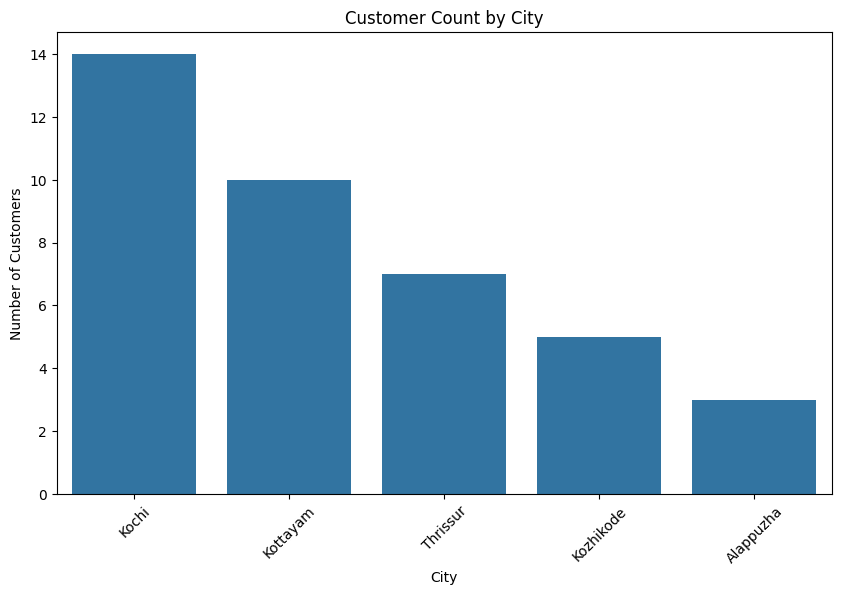

City with strongest customer base:
Kochi


In [ ]:
# 1. The marketing team wants to understand the customer population across cities. Create a visualization that allows them to compare customer counts by city. Which city appears to have the strongest customer base?
city_counts = customers["City"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_counts.index,
    y=city_counts.values
)

plt.title("Customer Count by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

print("City with strongest customer base:")
print(city_counts.idxmax())

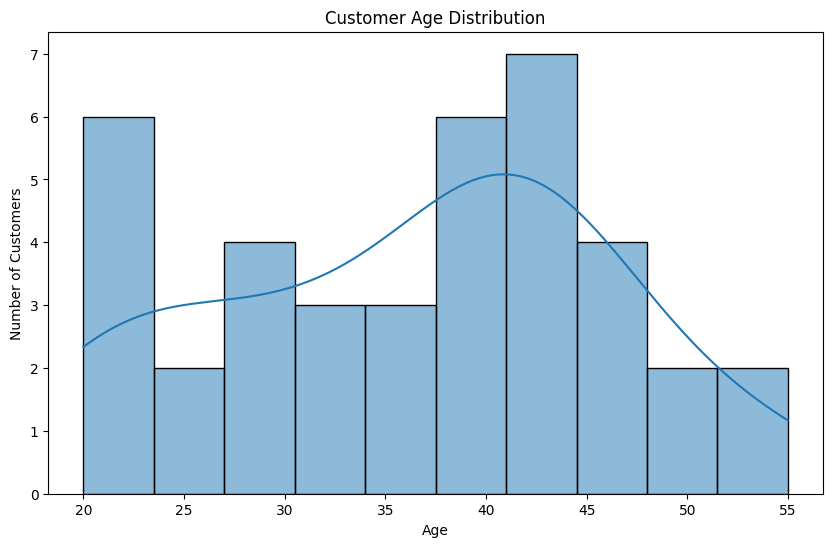

Mean Age: 36.333333333333336
Median Age: 39.0
Minimum Age: 20.0
Maximum Age: 55.0


In [ ]:
# 2. Understand the age distribution of customers. Choose an appropriate visualization and describe the age pattern.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=customers,
    x="Age",
    bins=10,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

print("Mean Age:", customers["Age"].mean())
print("Median Age:", customers["Age"].median())
print("Minimum Age:", customers["Age"].min())
print("Maximum Age:", customers["Age"].max())

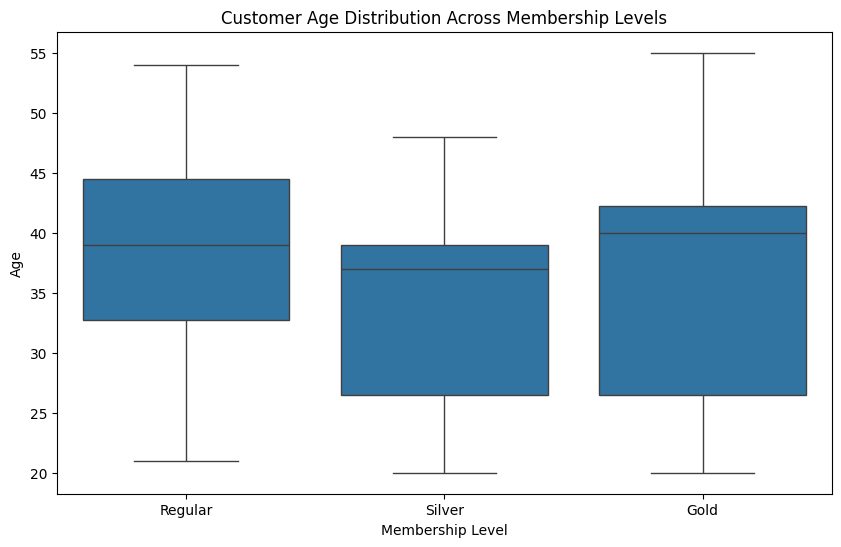

In [ ]:
# 3. Compare customer age distributions across membership levels. Identify whether groups appear to have different age patterns.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=customers,
    x="Membership",
    y="Age"
)

plt.title("Customer Age Distribution Across Membership Levels")
plt.xlabel("Membership Level")
plt.ylabel("Age")

plt.show()

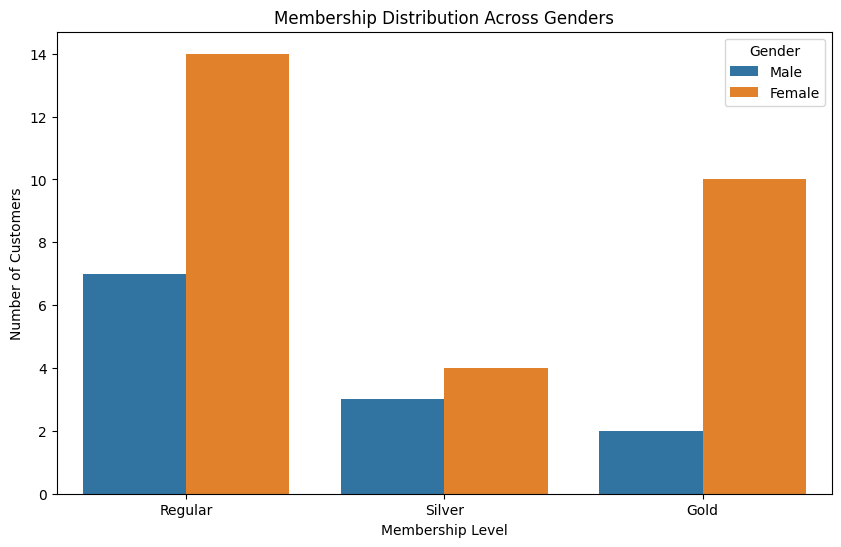

In [ ]:
# 4. Investigate whether membership is distributed differently across genders. Create a suitable visualization and explain the pattern.

plt.figure(figsize=(10, 6))

sns.countplot(
    data=customers,
    x="Membership",
    hue="Gender"
)

plt.title("Membership Distribution Across Genders")
plt.xlabel("Membership Level")
plt.ylabel("Number of Customers")

plt.show()

PART C — Product & Category Analysis

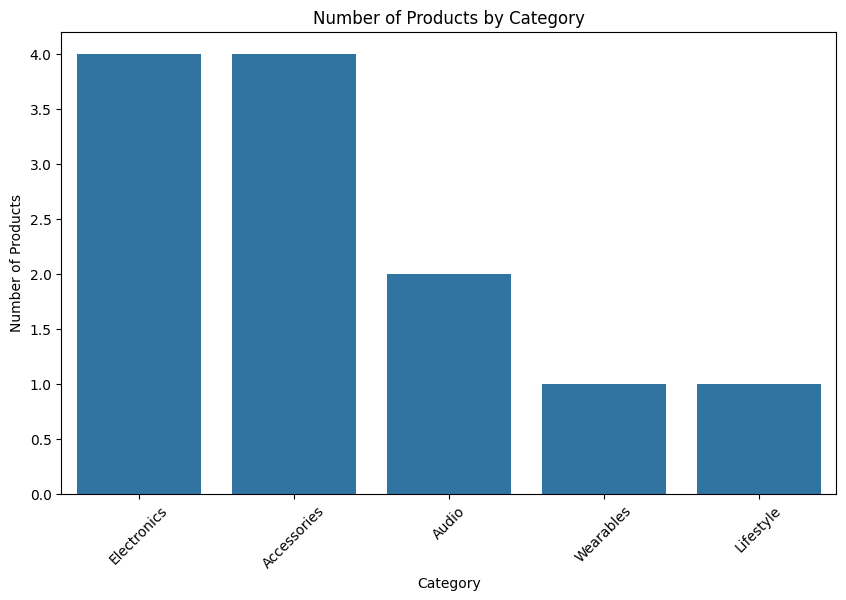

Category
Electronics    4
Accessories    4
Audio          2
Wearables      1
Lifestyle      1
Name: count, dtype: int64


In [ ]:
# 1. Visualize which product categories contain the largest number of products.
category_counts = products["Category"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Number of Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)

plt.show()

print(category_counts)

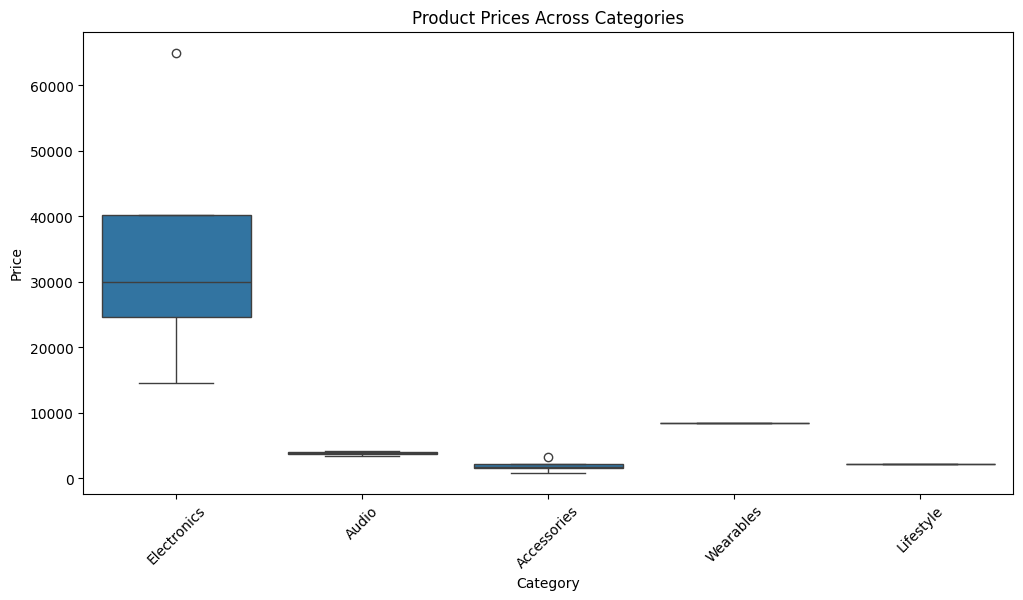

In [ ]:
# 2. Compare product prices across categories. Management wants to see both typical price and spread, including possible unusual prices. Choose a suitable visualization.
# Import the libraries required for visualization

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=products,
    x="Category",
    y="Price"
)

plt.title("Product Prices Across Categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45)

plt.show()

,min,max,Range
Category,,,
Electronics,14500,65000,50500
Accessories,900,3200,2300
Audio,3500,4200,700
Lifestyle,2200,2200,0
Wearables,8500,8500,0


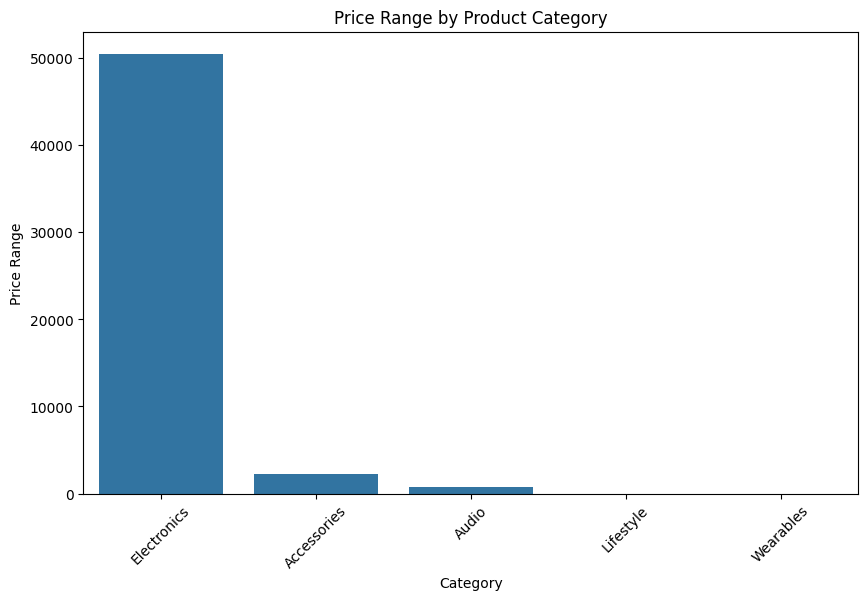

Category with widest price range: Electronics


In [ ]:
# 3. Which category appears to contain the widest range of product prices? Support your answer with a graph.
price_range = products.groupby("Category")["Price"].agg(
    ["min", "max"]
)

price_range["Range"] = (
    price_range["max"] - price_range["min"]
)

price_range = price_range.sort_values(
    "Range",
    ascending=False
)

display(price_range)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=price_range.reset_index(),
    x="Category",
    y="Range"
)

plt.title("Price Range by Product Category")
plt.xlabel("Category")
plt.ylabel("Price Range")
plt.xticks(rotation=45)

plt.show()

print(
    "Category with widest price range:",
    price_range.index[0]
)

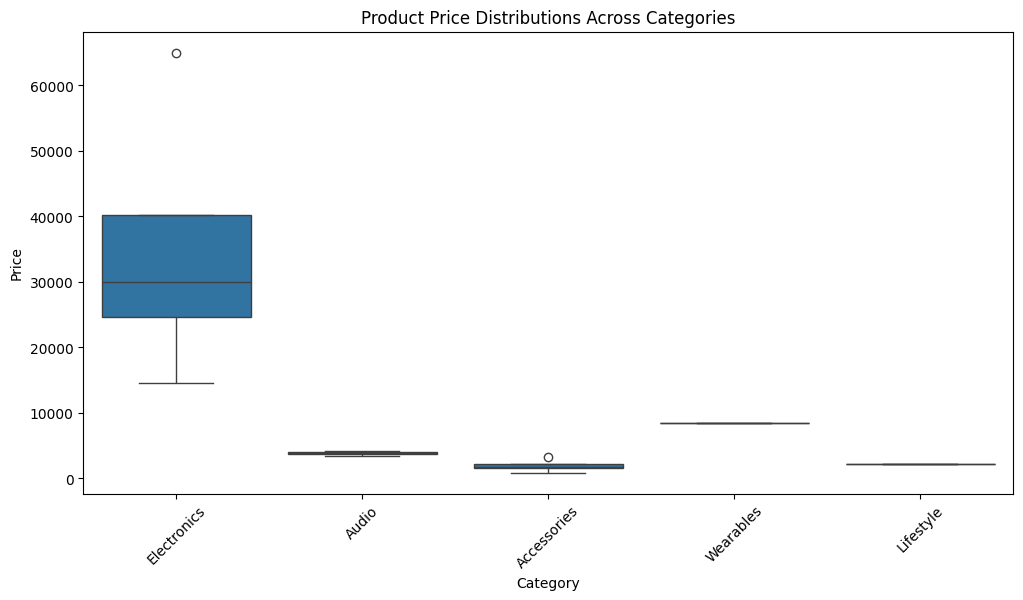

In [ ]:
# 4. Compare product price distributions across categories and identify any unusual prices.
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=products,
    x="Category",
    y="Price"
)

plt.title("Product Price Distributions Across Categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45)

plt.show()

PART D — Sales & Order Analysis

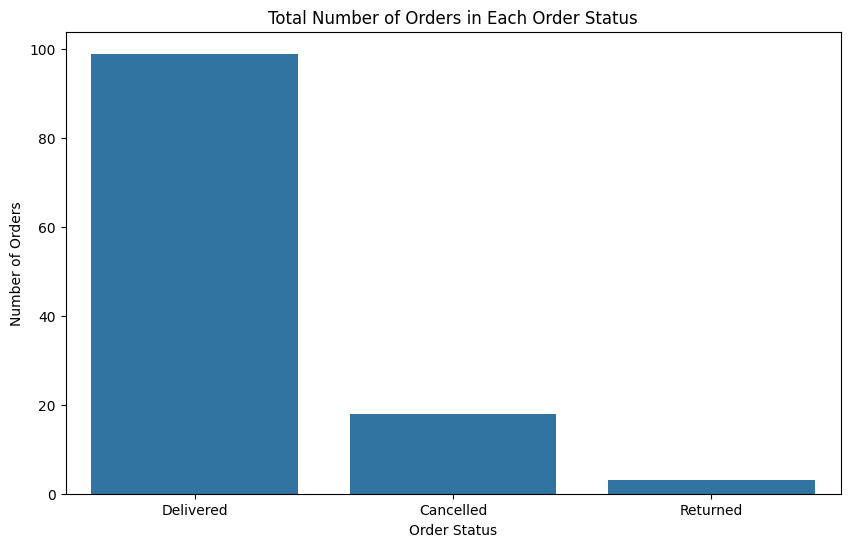

In [ ]:
# 1. Visualize the total number of orders in each order status.
plt.figure(figsize=(10, 6))

sns.countplot(
    data=orders,
    x="Status",
    order=orders["Status"].value_counts().index
)

plt.title("Total Number of Orders in Each Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()

In [ ]:
# Check the actual column names in the orders dataset

print(orders.columns.tolist())

['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date', 'Quantity', 'Discount_Percent', 'Delivery_Days', 'Rating', 'Status', 'Payment_Method']


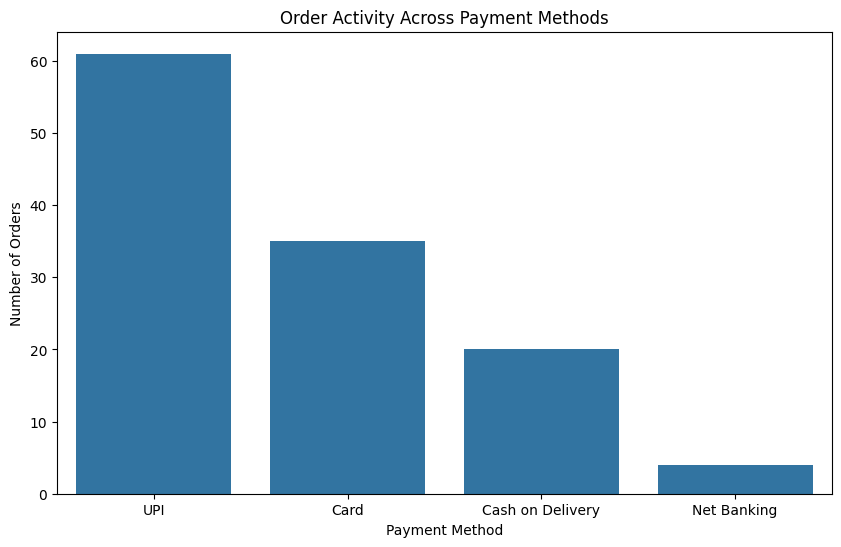

Most commonly used payment method: UPI


In [ ]:
# 2. Compare order activity across payment methods and identify the most commonly used method.
payment_counts = orders["Payment_Method"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values
)

plt.title("Order Activity Across Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.show()

print(
    "Most commonly used payment method:",
    payment_counts.idxmax()
)

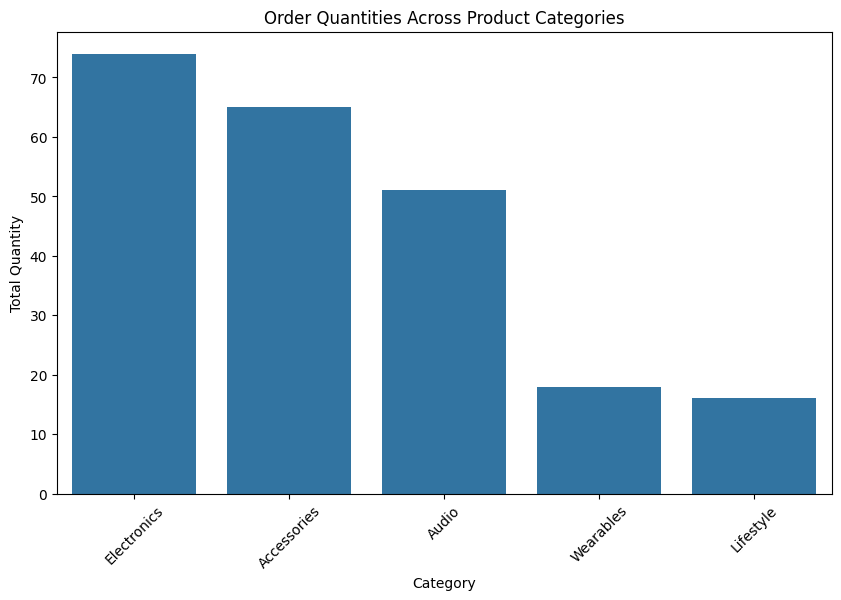

Category with largest quantity purchased: Electronics


In [ ]:
# 3. Compare order quantities across product categories and identify where customers purchase larger quantities.
category_quantity = df.groupby(
    "Category"
)["Quantity"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_quantity.index,
    y=category_quantity.values
)

plt.title("Order Quantities Across Product Categories")
plt.xlabel("Category")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)

plt.show()

print(
    "Category with largest quantity purchased:",
    category_quantity.idxmax()
)

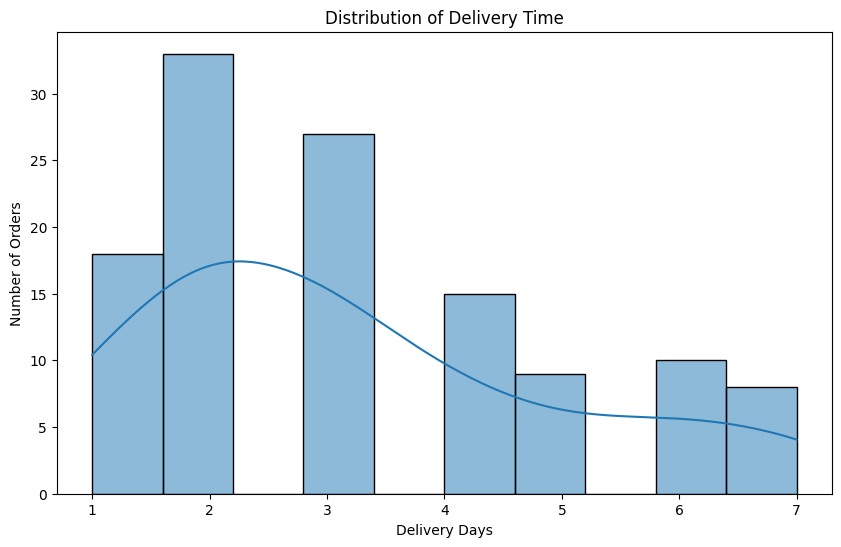

Mean: 3.216666666666667
Median: 3.0
Minimum: 1
Maximum: 7


In [ ]:
# 4. Understand the distribution of delivery time. Describe whether delivery times are concentrated or widely spread.

plt.figure(figsize=(10, 6))

sns.histplot(
    data=orders,
    x="Delivery_Days",
    bins=10,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")

plt.show()

print("Mean:", orders["Delivery_Days"].mean())
print("Median:", orders["Delivery_Days"].median())
print("Minimum:", orders["Delivery_Days"].min())
print("Maximum:", orders["Delivery_Days"].max())

In [ ]:
print(orders.columns.tolist())

['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date', 'Quantity', 'Discount_Percent', 'Delivery_Days', 'Rating', 'Status', 'Payment_Method']


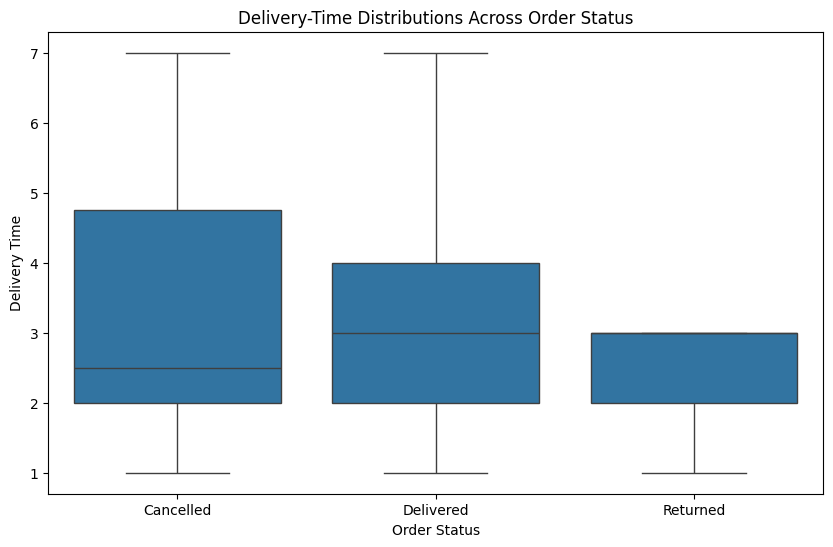

In [ ]:
# 5. Compare delivery-time distributions across order status. What does the graph suggest?
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=orders,
    x="Status",
    y="Delivery_Days"
)

plt.title("Delivery-Time Distributions Across Order Status")
plt.xlabel("Order Status")
plt.ylabel("Delivery Time")

plt.show()

PART E — Customer Experience Analysis

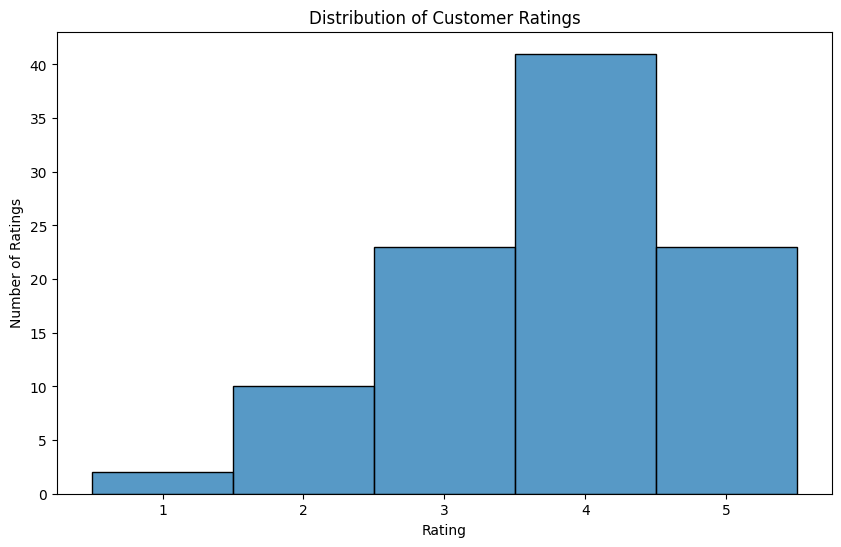

Rating
1.0     2
2.0    10
3.0    23
4.0    41
5.0    23
Name: count, dtype: int64


In [ ]:
# 1. Visualize the distribution of customer ratings and describe the overall pattern.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=orders,
    x="Rating",
    bins=5,
    discrete=True
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

print(
    orders["Rating"].value_counts().sort_index()
)

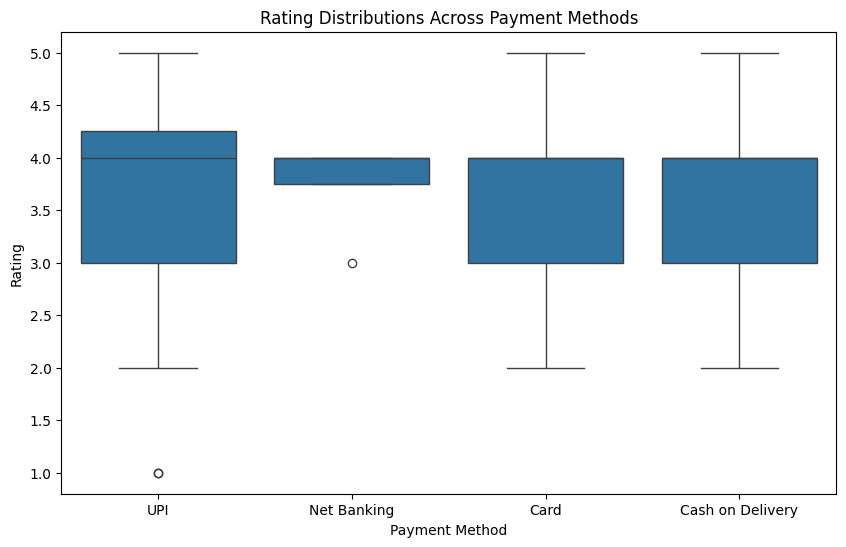

In [ ]:
# 2. Compare rating distributions across payment methods. Is there a noticeable difference?
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=orders,
    x="Payment_Method",
    y="Rating"
)

plt.title("Rating Distributions Across Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Rating")

plt.show()

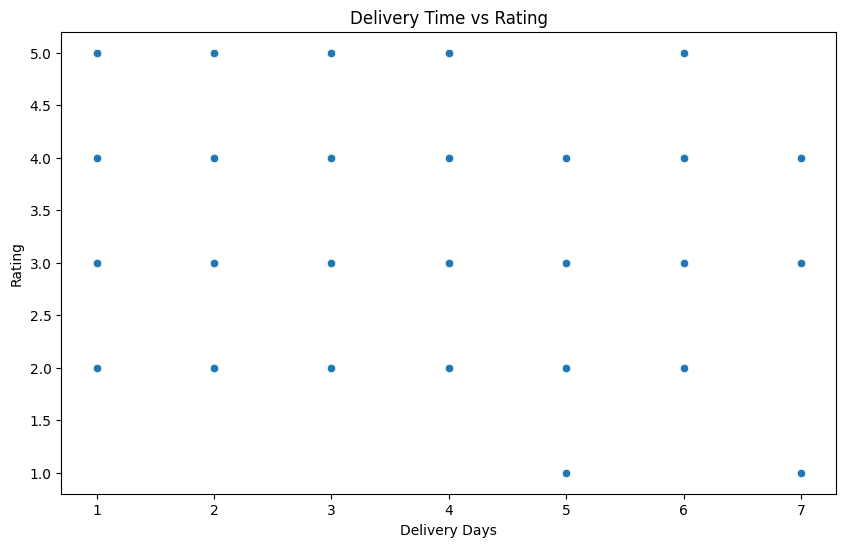

Correlation: -0.246


In [ ]:
# 3. Investigate whether longer delivery times are associated with lower ratings.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=orders,
    x="Delivery_Days",
    y="Rating"
)

plt.title("Delivery Time vs Rating")
plt.xlabel("Delivery Days")
plt.ylabel("Rating")

plt.show()

correlation = orders["Delivery_Days"].corr(
    orders["Rating"]
)

print("Correlation:", round(correlation, 3))

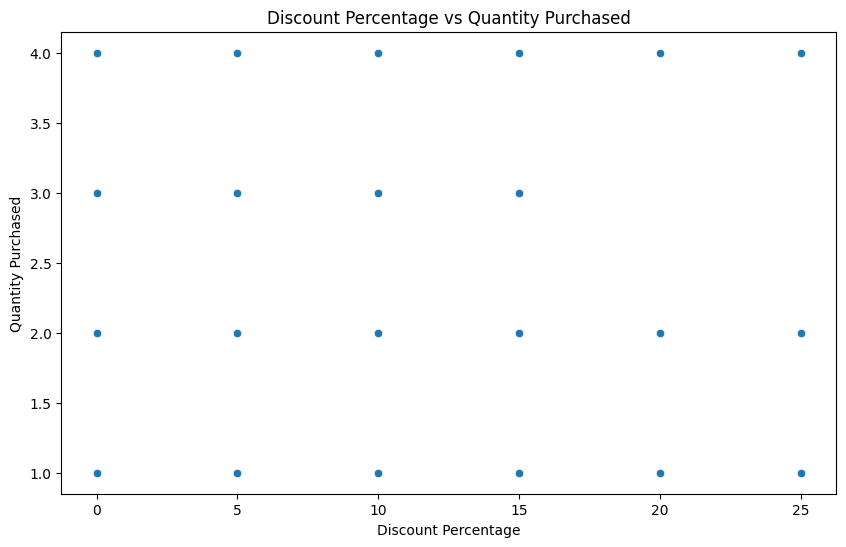

Correlation: -0.068


In [ ]:
# 4. Investigate whether discount percentage is related to quantity purchased.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=orders,
    x="Discount_Percent",
    y="Quantity"
)

plt.title("Discount Percentage vs Quantity Purchased")
plt.xlabel("Discount Percentage")
plt.ylabel("Quantity Purchased")

plt.show()

correlation = orders["Discount_Percent"].corr(
    orders["Quantity"]
)

print("Correlation:", round(correlation, 3))

In [ ]:
# 5. Identify one customer-experience issue that deserves further investigation based on your visual analysis.

delivery_rating_correlation = orders[
    "Delivery_Days"
].corr(
    orders["Rating"]
)

print(
    "Delivery Time vs Rating Correlation:",
    round(delivery_rating_correlation, 3)
)

if delivery_rating_correlation < -0.3:
    print(
        "Issue for further investigation: Longer delivery times "
        "appear to be associated with lower customer ratings."
    )

elif delivery_rating_correlation > 0.3:
    print(
        "The data shows a positive relationship between delivery "
        "time and rating. This unusual pattern deserves investigation."
    )

else:
    print(
        "Delivery time and rating do not show a strong relationship. "
        "Other customer-experience factors should be investigated."
    )

Delivery Time vs Rating Correlation: -0.246
Delivery time and rating do not show a strong relationship. Other customer-experience factors should be investigated.


PART F — Relationship Analysis

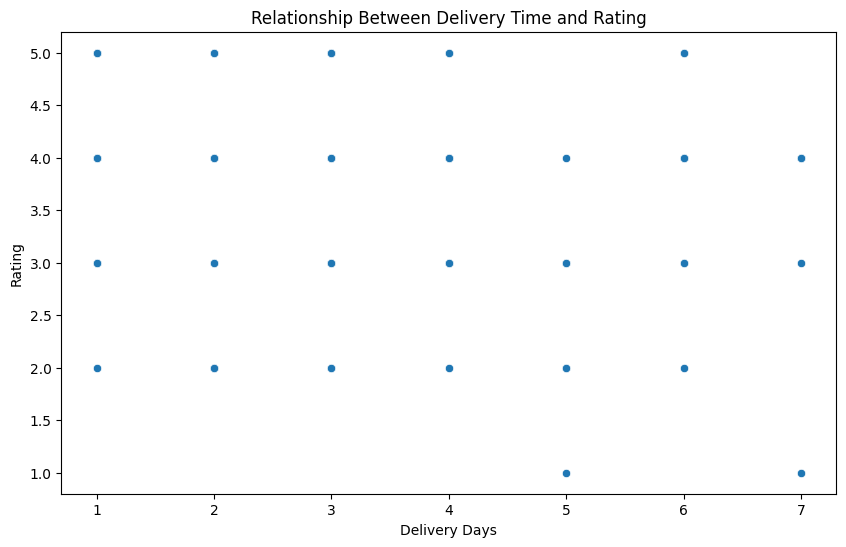

In [ ]:
# 1. Investigate the relationship between delivery time and rating.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=orders,
    x="Delivery_Days",
    y="Rating"
)

plt.title("Relationship Between Delivery Time and Rating")
plt.xlabel("Delivery Days")
plt.ylabel("Rating")

plt.show()

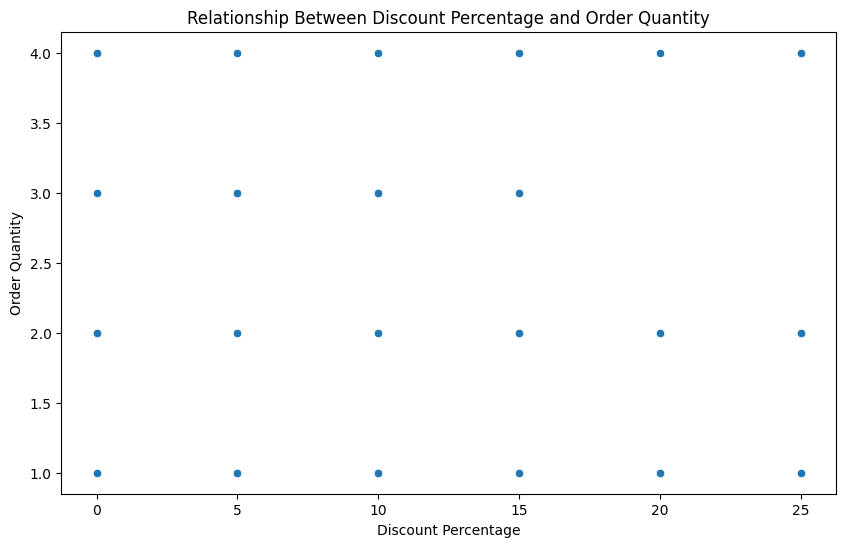

In [ ]:
# 2. Investigate the relationship between discount percentage and order quantity.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=orders,
    x="Discount_Percent",
    y="Quantity"
)

plt.title("Relationship Between Discount Percentage and Order Quantity")
plt.xlabel("Discount Percentage")
plt.ylabel("Order Quantity")

plt.show()

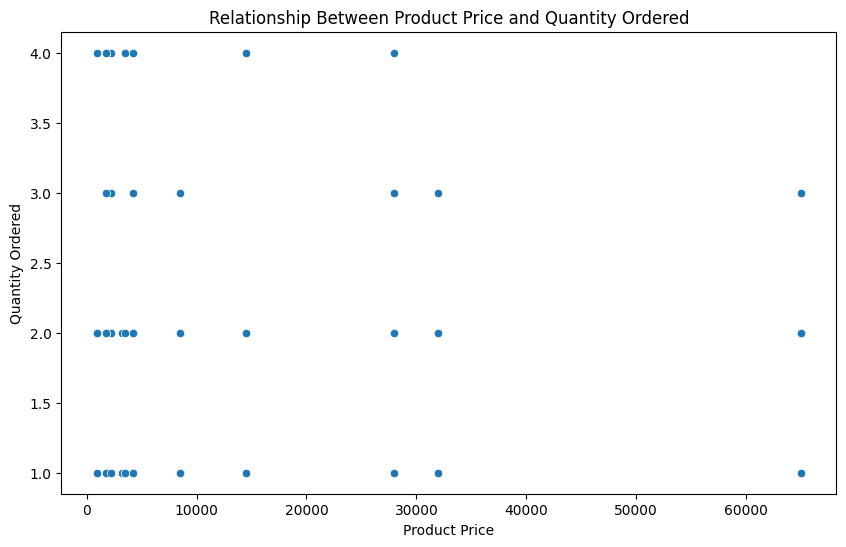

In [ ]:
# 3. Investigate the relationship between product price and quantity ordered.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price",
    y="Quantity"
)

plt.title("Relationship Between Product Price and Quantity Ordered")
plt.xlabel("Product Price")
plt.ylabel("Quantity Ordered")

plt.show()

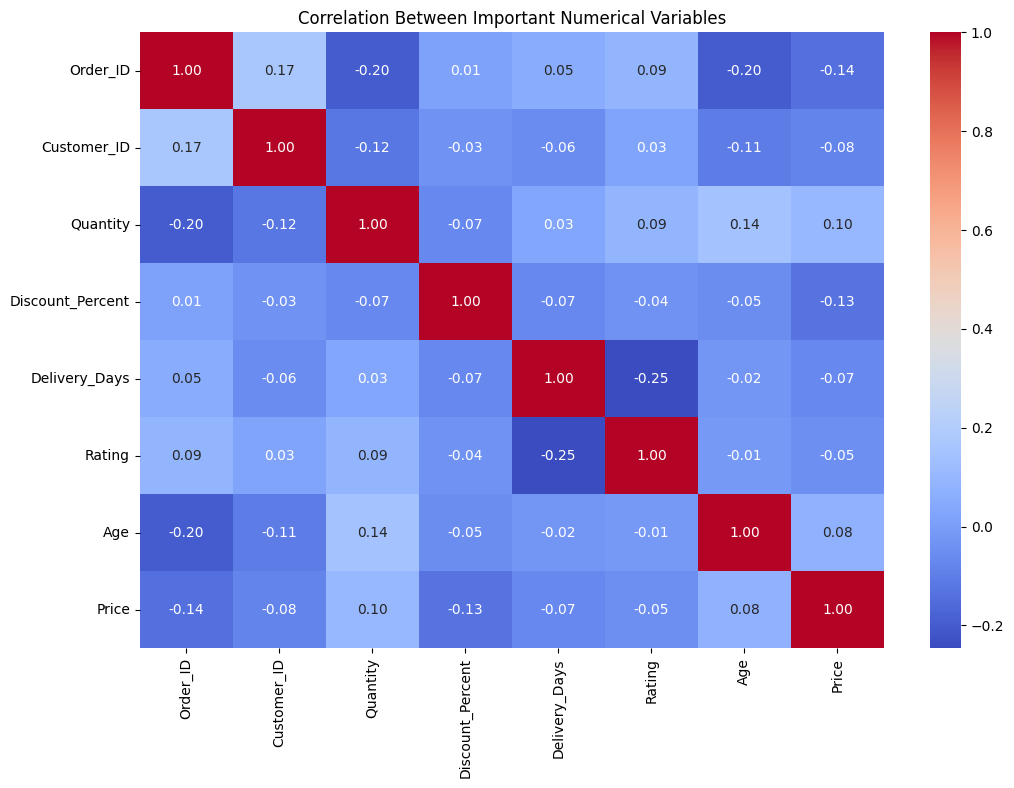

In [ ]:
# 4. Select important numerical variables and create a visualization that helps inspect their correlations.
numerical_data = df.select_dtypes(
    include=np.number
)

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Important Numerical Variables")

plt.show()

In [ ]:
# 5. Identify one relationship that appears strong and one that appears weak or unclear. Explain how the graph led to your conclusion.
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

# Remove self-correlations
corr_pairs = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
).stack()

corr_pairs = corr_pairs.sort_values(
    key=abs,
    ascending=False
)

print("Strongest relationship:")
print(corr_pairs.head(1))

print("\nWeakest relationship:")
print(corr_pairs.sort_values(
    key=abs
).head(1))

Strongest relationship:
Delivery_Days  Rating   -0.24594
dtype: float64

Weakest relationship:
Order_ID  Discount_Percent    0.012136
dtype: float64


PART G — Multi-Variable Exploration

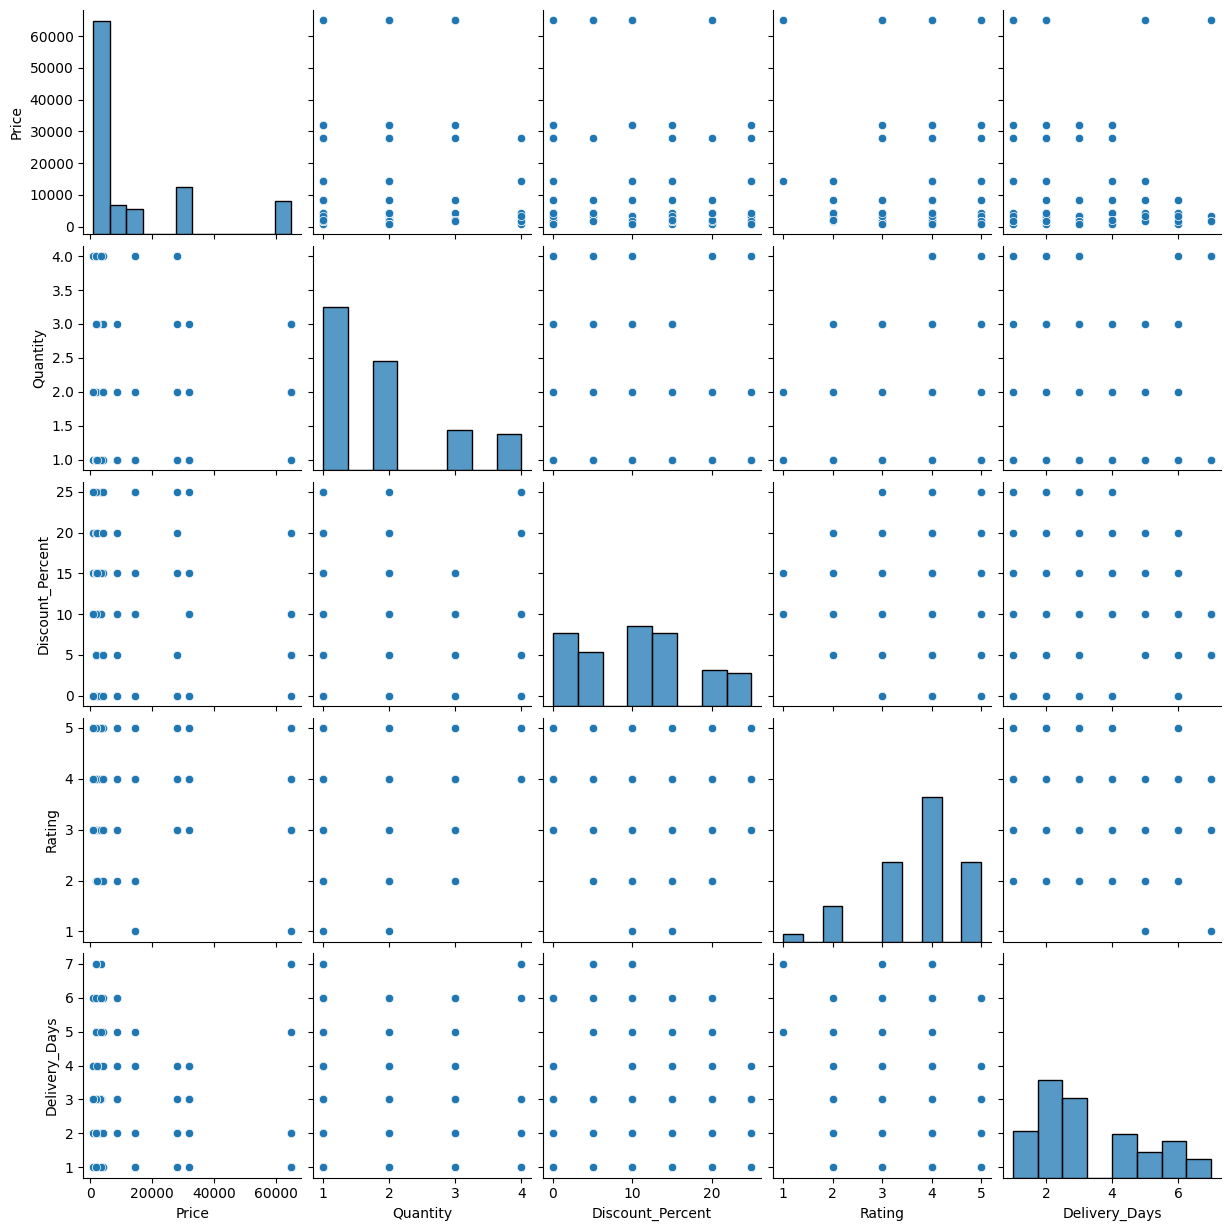

In [ ]:
# 1. Create a visualization that allows you to examine several numerical variables together and identify potentially interesting relationships.
selected_columns = [
    "Price",
    "Quantity",
    "Discount_Percent",
    "Rating",
    "Delivery_Days"
]

sns.pairplot(
    df[selected_columns].dropna()
)

plt.show()

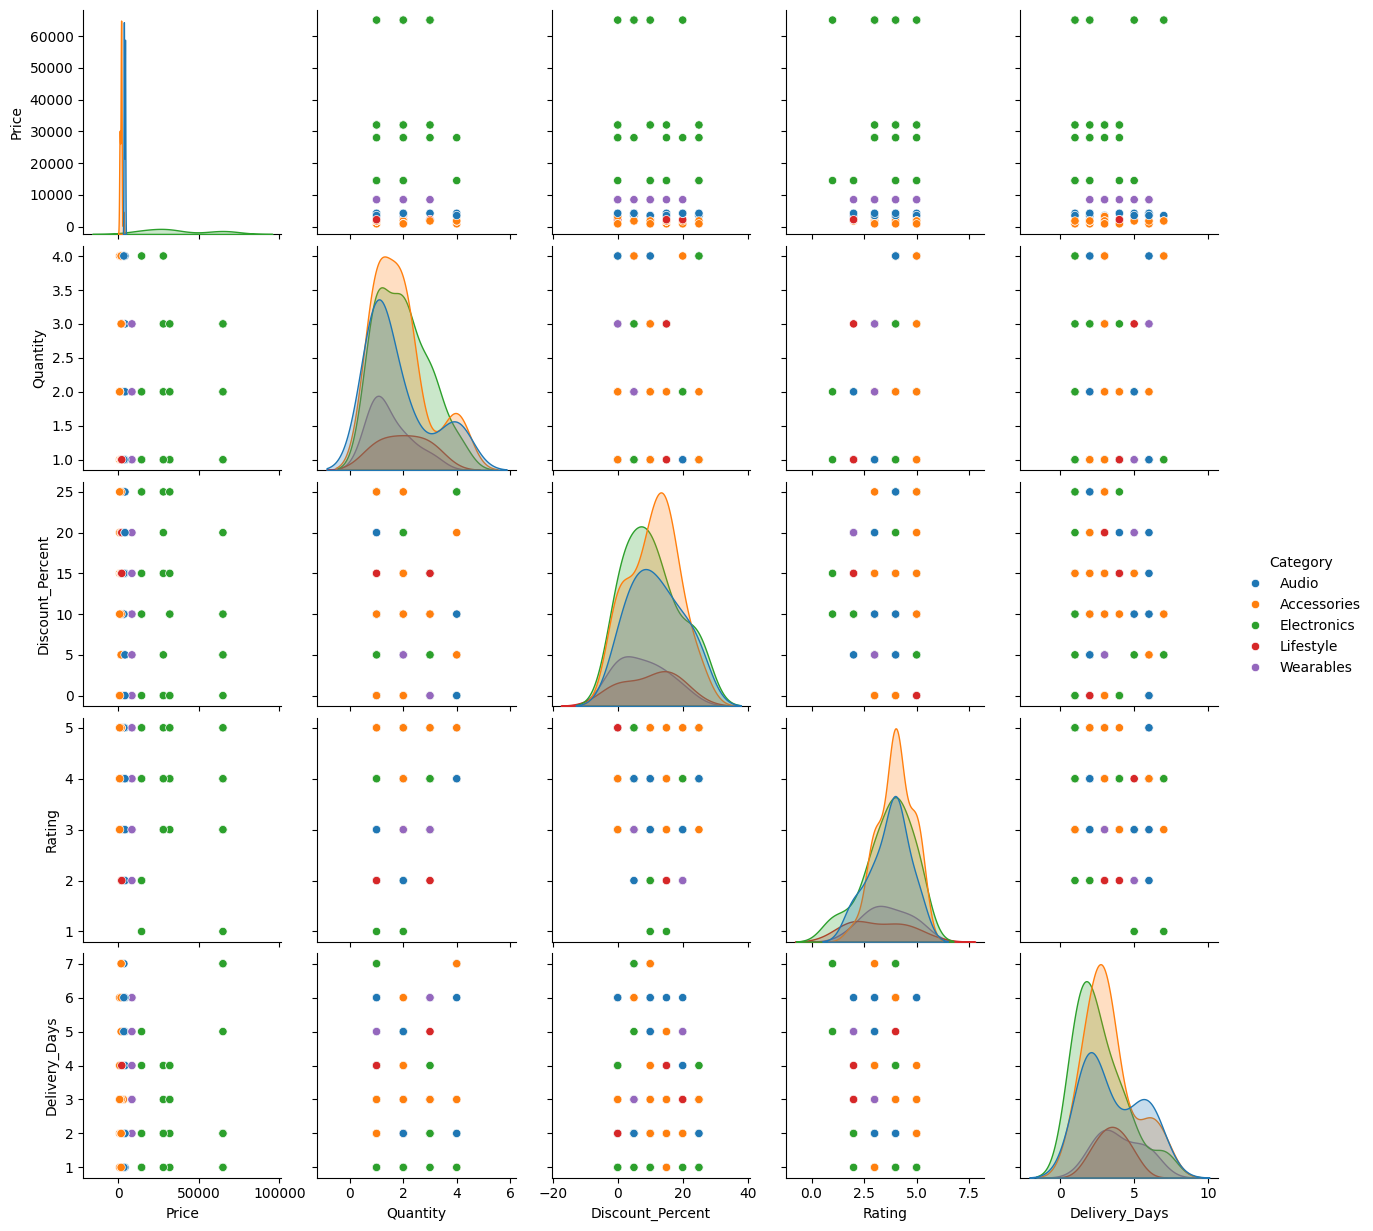

In [ ]:
# 2. Use a categorical variable to separate or compare groups in your multi-variable analysis. Explain what additional information becomes visible.
sns.pairplot(
    df[
        selected_columns + ["Category"]
    ].dropna(),
    hue="Category"
)

plt.show()

In [ ]:
# 3. Identify one relationship that looks strong and one that looks weak or unclear.
correlation_matrix = df[
    selected_columns
].corr()

corr_pairs = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
).stack()

strongest = corr_pairs.sort_values(
    key=abs,
    ascending=False
).head(1)

weakest = corr_pairs.sort_values(
    key=abs
).head(1)

print("Strong relationship:")
print(strongest)

print("\nWeak or unclear relationship:")
print(weakest)

Strong relationship:
Rating  Delivery_Days   -0.24594
dtype: float64

Weak or unclear relationship:
Quantity  Delivery_Days    0.02693
dtype: float64


PART H — Business Decision Challenge

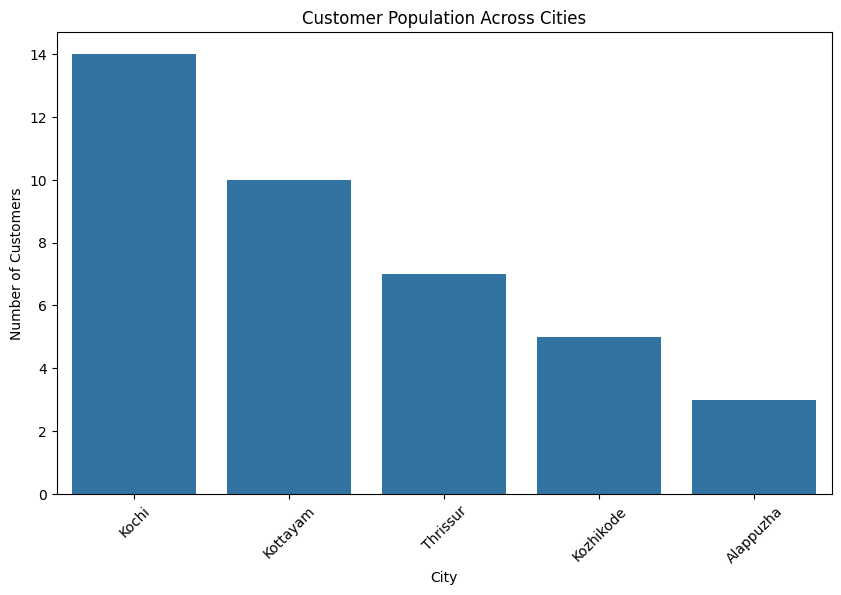

Recommended city: Kochi


In [ ]:
# 1. Recommend one city for more customer-acquisition attention. Justify your decision with visual evidence.
city_counts = customers["City"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_counts.index,
    y=city_counts.values
)

plt.title("Customer Population Across Cities")
plt.xlabel("City")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

recommended_city = city_counts.idxmax()

print(
    "Recommended city:",
    recommended_city
)

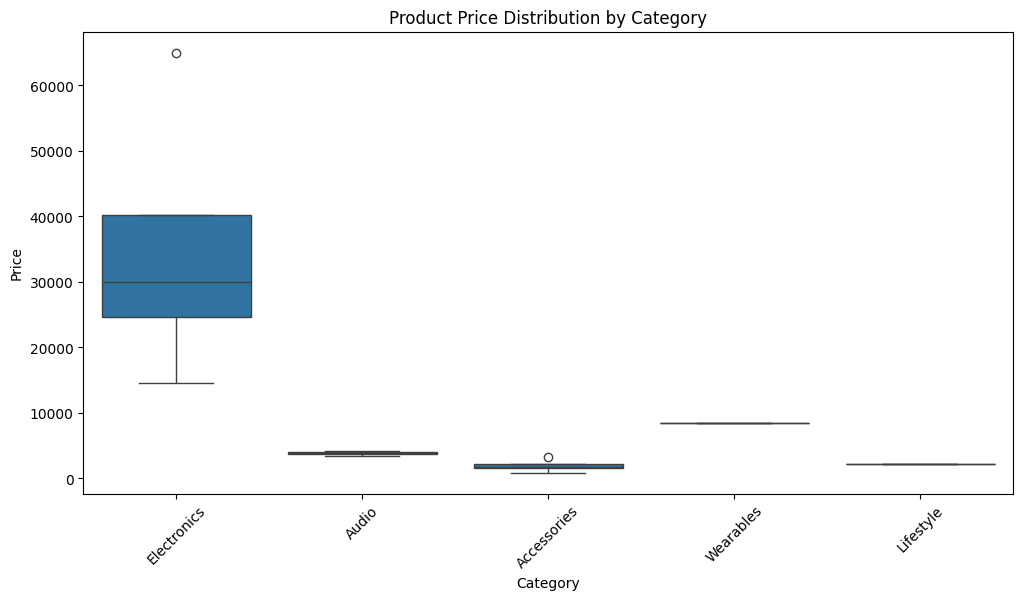

Recommended category for pricing review: Electronics

Price ranges:
Category
Electronics    50500
Accessories     2300
Audio            700
Lifestyle          0
Wearables          0
Name: Price, dtype: int64


In [ ]:
# 2. Recommend one product category for pricing review. Support your decision visually.
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=products,
    x="Category",
    y="Price"
)

plt.title("Product Price Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45)

plt.show()

category_price_range = products.groupby(
    "Category"
)["Price"].agg(
    lambda x: x.max() - x.min()
)

recommended_category = category_price_range.idxmax()

print(
    "Recommended category for pricing review:",
    recommended_category
)

print("\nPrice ranges:")
print(
    category_price_range.sort_values(
        ascending=False
    )
)

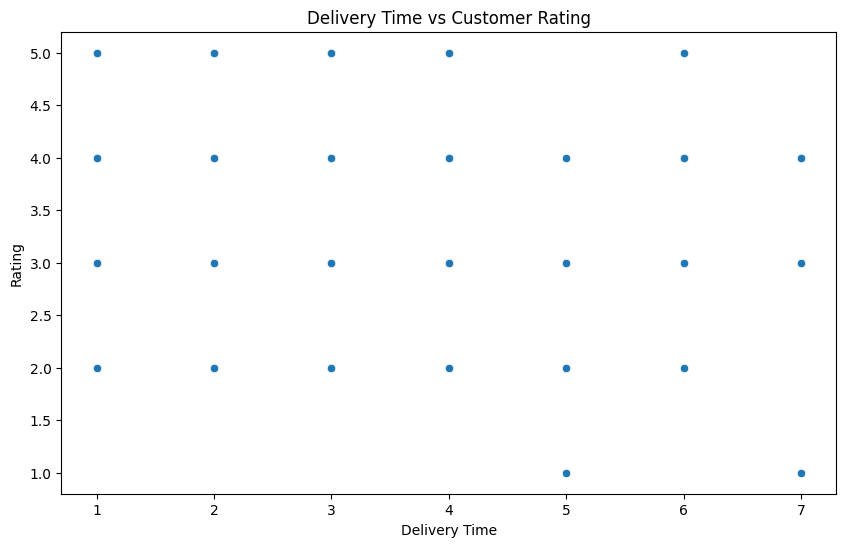

Delivery Time vs Rating correlation: -0.246


In [ ]:
# 3. Identify the most important relationship to investigate if the company wants to reduce delivery-related customer dissatisfaction.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=orders,
    x="Delivery_Days",
    y="Rating"
)

plt.title("Delivery Time vs Customer Rating")
plt.xlabel("Delivery Time")
plt.ylabel("Rating")

plt.show()

correlation = orders[
    "Delivery_Days"
].corr(
    orders["Rating"]
)

print(
    "Delivery Time vs Rating correlation:",
    round(correlation, 3)
)

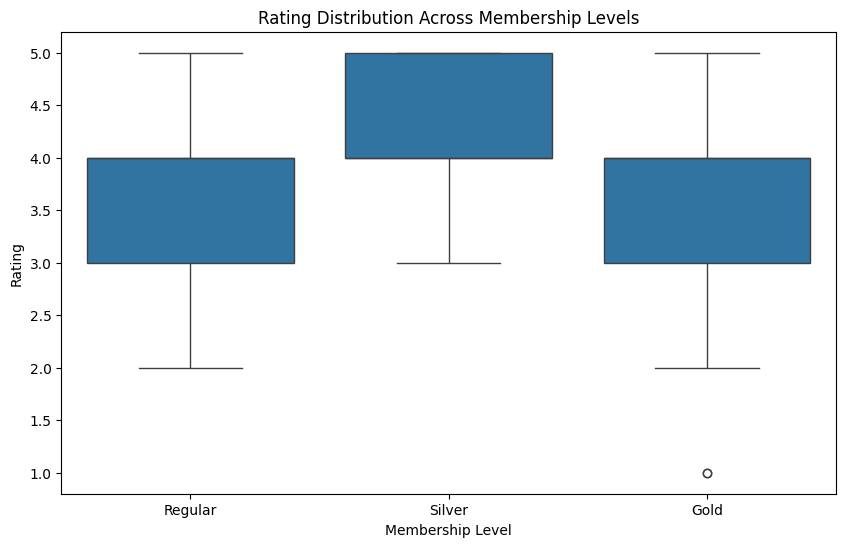

Average rating by membership level:


,Rating
Membership,
Silver,4.166667
Regular,3.642857
Gold,3.640000


Group with highest average rating: Silver
Group with lowest average rating: Gold


In [ ]:
# 4. Define a customer group that may have a different rating or delivery experience. Support your conclusion with a suitable visualization.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Membership",
    y="Rating"
)

plt.title("Rating Distribution Across Membership Levels")
plt.xlabel("Membership Level")
plt.ylabel("Rating")

plt.show()

print("Average rating by membership level:")

membership_rating = df.groupby(
    "Membership"
)["Rating"].mean().sort_values(
    ascending=False
)

display(membership_rating)

print(
    "Group with highest average rating:",
    membership_rating.idxmax()
)

print(
    "Group with lowest average rating:",
    membership_rating.idxmin()
)

In [ ]:
print(customers.columns.tolist())

['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Membership']


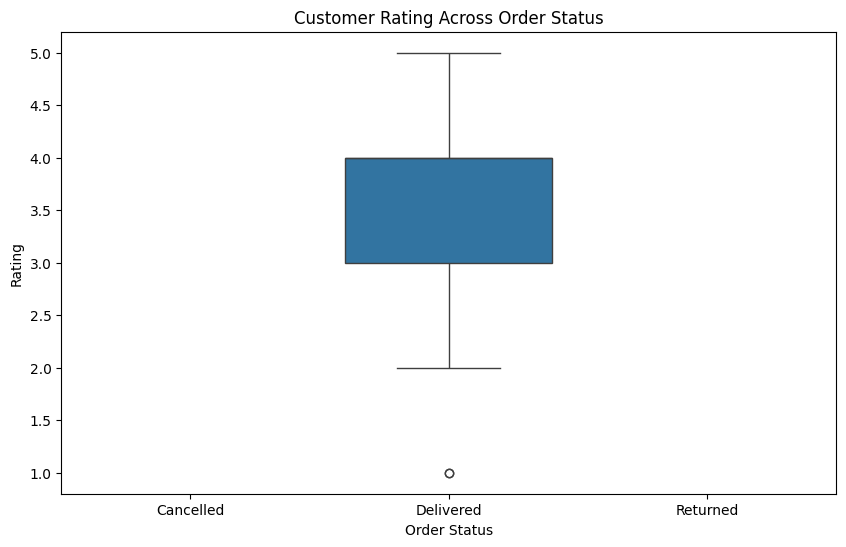

Average rating by order status:


,Rating
Status,
Delivered,3.737374
Cancelled,NaN
Returned,NaN


Order status with highest average rating: Delivered
Order status with lowest average rating: Delivered


In [ ]:
# 5. Create one additional business question that can be answered from the dataset, visualize it, interpret it, and provide a recommendation.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Status",
    y="Rating"
)

plt.title("Customer Rating Across Order Status")
plt.xlabel("Order Status")
plt.ylabel("Rating")

plt.show()

status_rating = df.groupby(
    "Status"
)["Rating"].mean().sort_values(
    ascending=False
)

print("Average rating by order status:")
display(status_rating)

print(
    "Order status with highest average rating:",
    status_rating.idxmax()
)

print(
    "Order status with lowest average rating:",
    status_rating.idxmin()
)

PART I — Final EDA Challenge

In [ ]:
# 1. Prepare a clean analytical dataset by combining the required information from customers, products, and orders.
# Remove exact duplicate records
customers_clean = customers.drop_duplicates()
products_clean = products.drop_duplicates()
orders_clean = orders.drop_duplicates()

# Combine orders and customers
customer_orders = pd.merge(
    orders_clean,
    customers_clean,
    on="Customer_ID",
    how="left"
)

# Combine with products
df_clean = pd.merge(
    customer_orders,
    products_clean,
    on="Product_ID",
    how="left"
)

print("Clean analytical dataset shape:")
print(df_clean.shape)

display(df_clean.head())

Clean analytical dataset shape:
(120, 18)


,Order_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Percent,Delivery_Days,Rating,Status,Payment_Method,Customer_Name,Age,Gender,City,Membership,Product,Category,Price
0,5001,1012,P05,2026-01-01,1,5.0,2,NaN,Cancelled,UPI,Kavya,21.0,Female,Kottayam,Regular,Mouse,Accessories,900
1,5002,1039,P12,2026-01-02,1,0.0,4,3.0,Delivered,UPI,Devika,38.0,Male,Thrissur,Silver,Speaker,Audio,4200
2,5003,1002,P03,2026-01-04,1,15.0,2,4.0,Delivered,Net Banking,Meera,33.0,Female,Thrissur,Regular,Headphones,Audio,3500
3,5004,1003,P04,2026-01-05,1,15.0,2,4.0,Delivered,Card,Rahul,26.0,Male,Kochi,Silver,Keyboard,Accessories,1800
4,5005,1037,P03,2026-01-07,4,25.0,3,5.0,Delivered,Card,Keerthi,44.0,Male,Thrissur,Regular,Headphones,Audio,3500


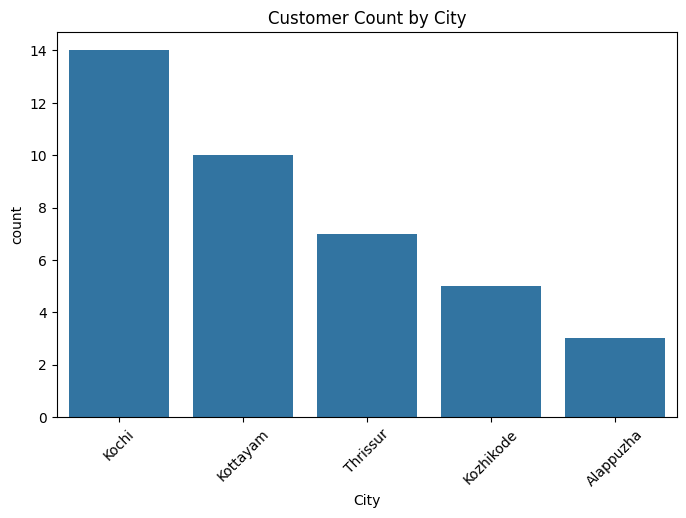

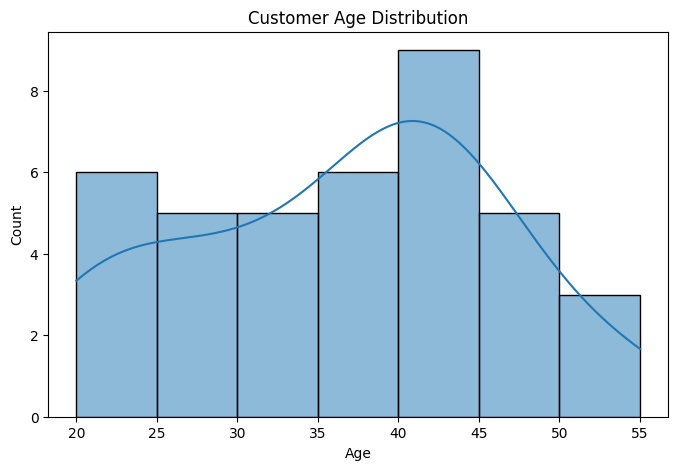

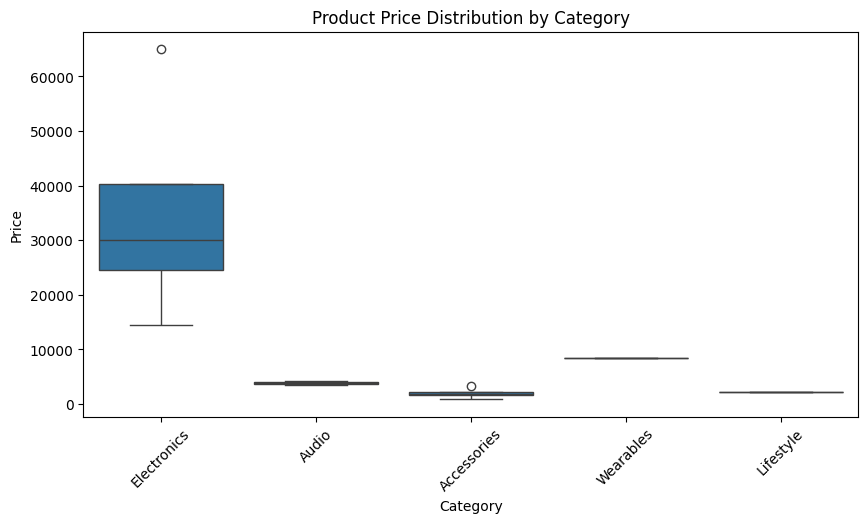

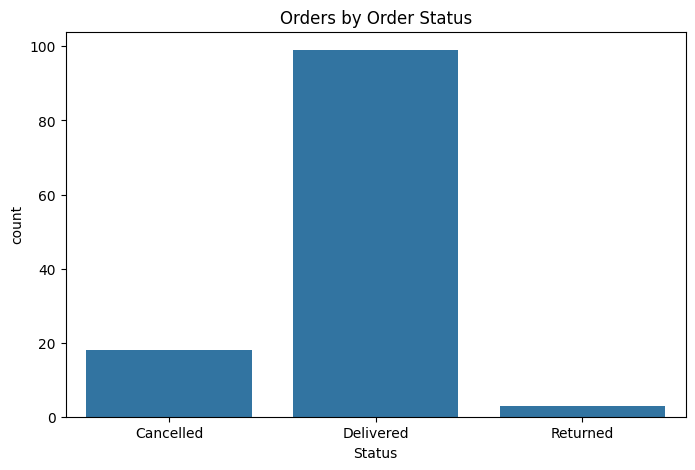

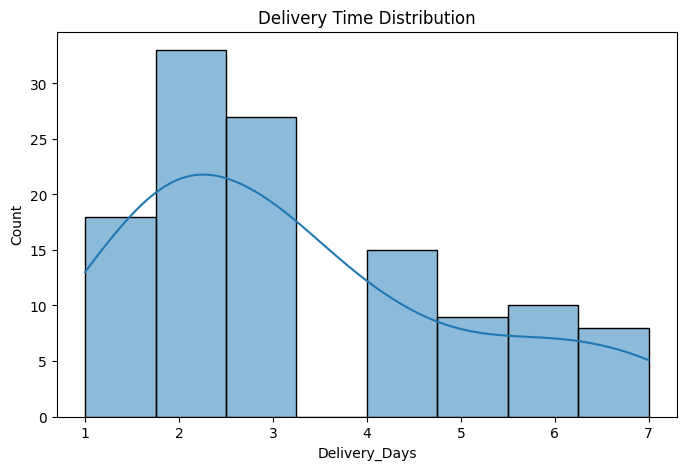

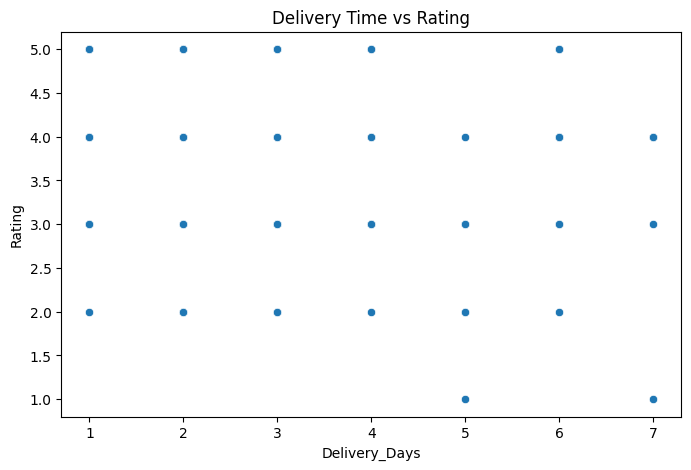

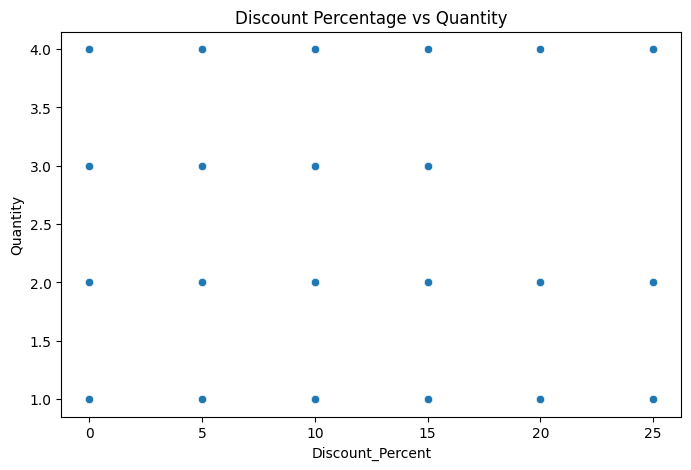

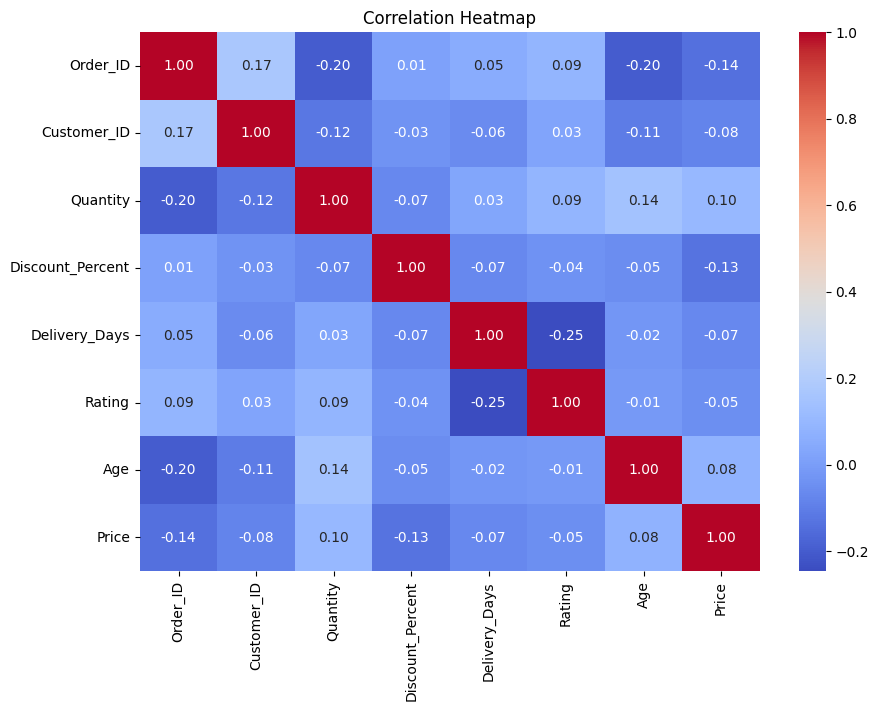

In [ ]:
# 2. Create at least 8 meaningful Seaborn visualizations covering different analytical questions.
# Visualization 1 — Customer population across cities
plt.figure(figsize=(8, 5))
sns.countplot(
    data=customers,
    x="City",
    order=customers["City"].value_counts().index
)
plt.title("Customer Count by City")
plt.xticks(rotation=45)
plt.show()


# Visualization 2 — Age distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    data=customers,
    x="Age",
    kde=True
)
plt.title("Customer Age Distribution")
plt.show()


# Visualization 3 — Product prices across categories
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=products,
    x="Category",
    y="Price"
)
plt.title("Product Price Distribution by Category")
plt.xticks(rotation=45)
plt.show()


# Visualization 4 — Order status
plt.figure(figsize=(8, 5))
sns.countplot(
    data=orders,
    x="Status"
)
plt.title("Orders by Order Status")
plt.show()


# Visualization 5 — Delivery time distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    data=orders,
    x="Delivery_Days",
    kde=True
)
plt.title("Delivery Time Distribution")
plt.show()


# Visualization 6 — Delivery time and rating
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=orders,
    x="Delivery_Days",
    y="Rating"
)
plt.title("Delivery Time vs Rating")
plt.show()


# Visualization 7 — Discount and quantity
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=orders,
    x="Discount_Percent",
    y="Quantity"
)
plt.title("Discount Percentage vs Quantity")
plt.show()


# Visualization 8 — Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df_clean.select_dtypes(
        include=np.number
    ).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# 3. Do not use the same visualization blindly for every question.

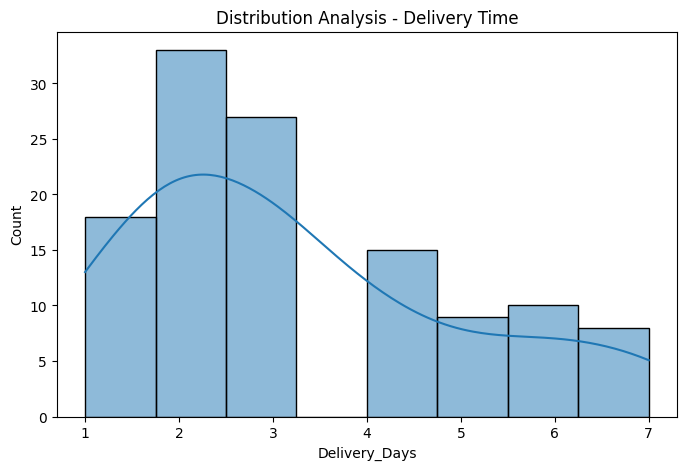

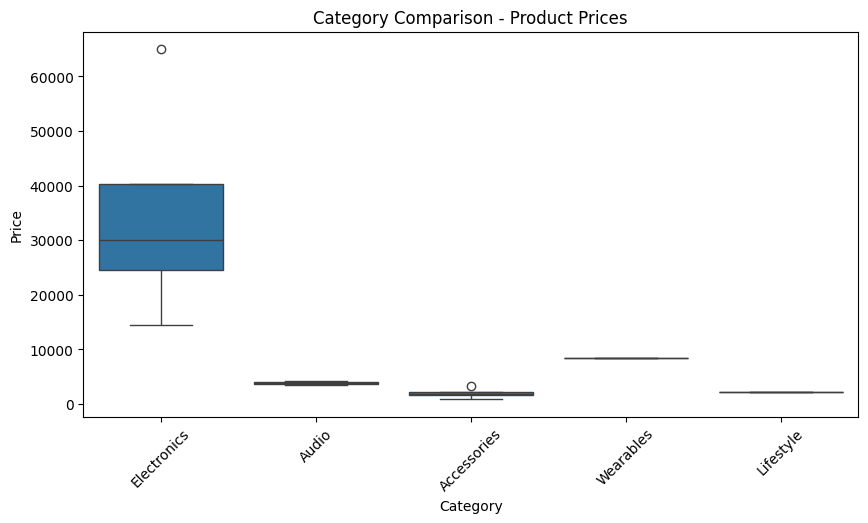

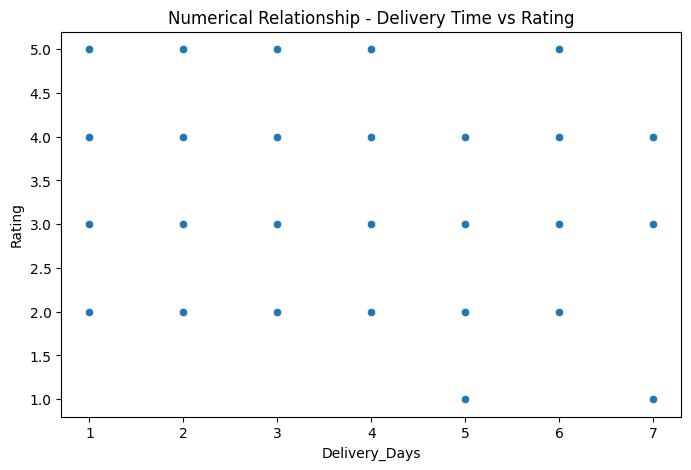

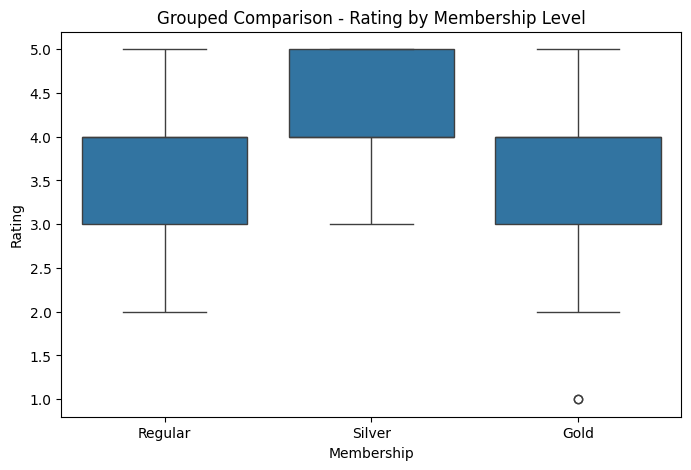

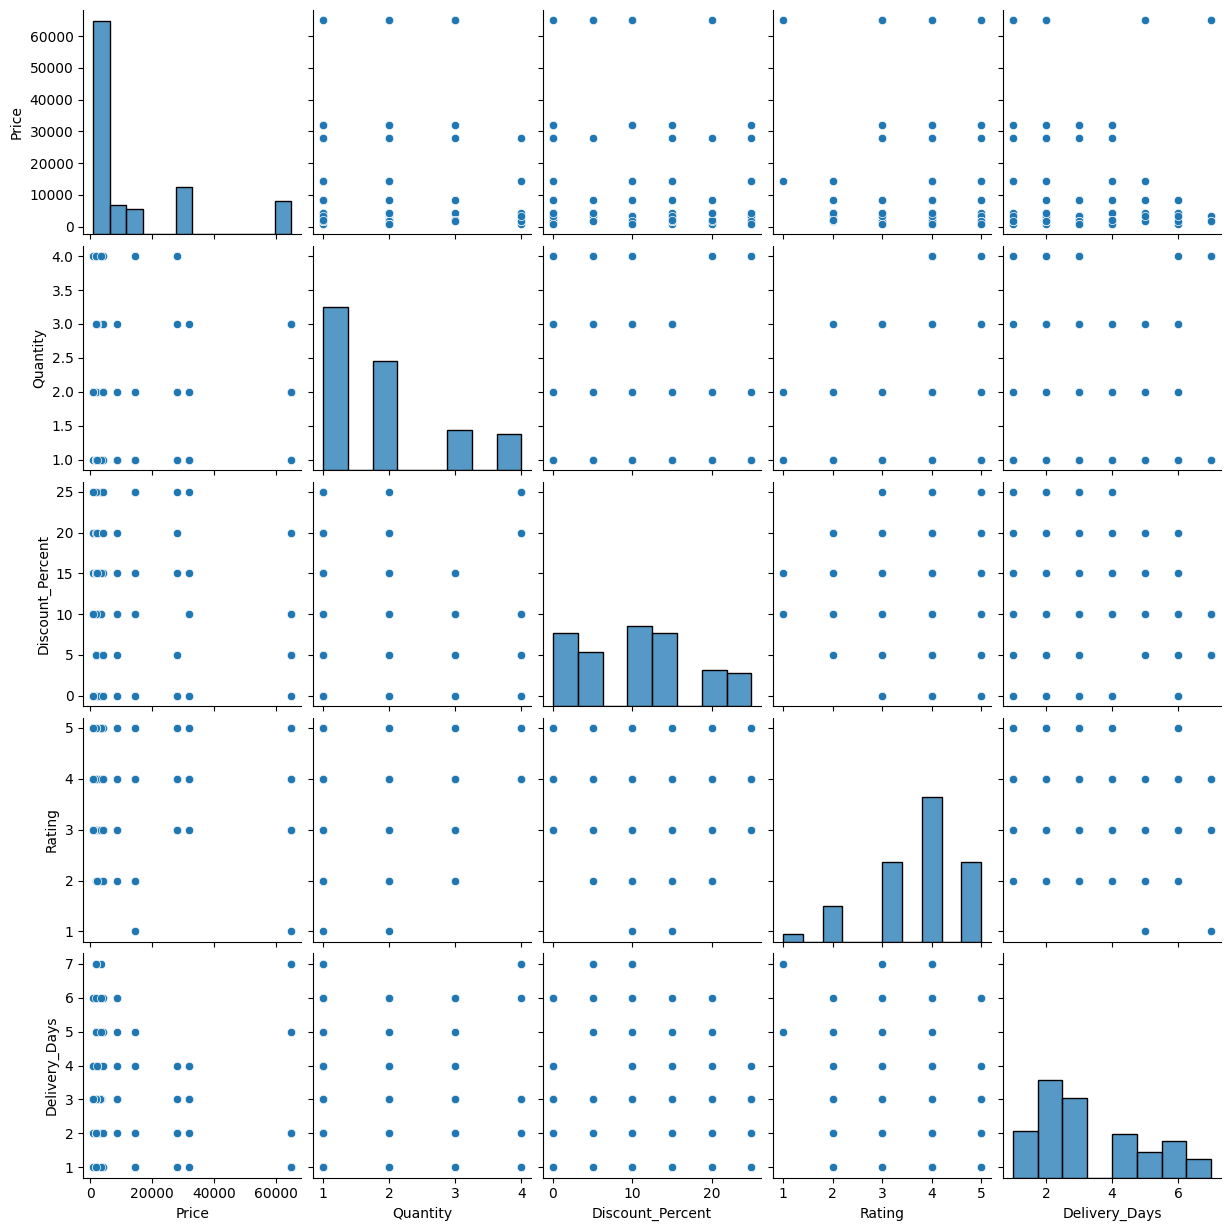

In [ ]:
# 4. Include at least one distribution analysis, one category comparison, one numerical relationship, one grouped comparison using an additional categorical variable, and one multi-variable analysis.
# Distribution analysis
plt.figure(figsize=(8, 5))
sns.histplot(
    data=orders,
    x="Delivery_Days",
    kde=True
)
plt.title("Distribution Analysis - Delivery Time")
plt.show()


# Category comparison
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=products,
    x="Category",
    y="Price"
)
plt.title("Category Comparison - Product Prices")
plt.xticks(rotation=45)
plt.show()


# Numerical relationship
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=orders,
    x="Delivery_Days",
    y="Rating"
)
plt.title("Numerical Relationship - Delivery Time vs Rating")
plt.show()


# Grouped comparison using categorical variable
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="Membership",
    y="Rating"
)
plt.title("Grouped Comparison - Rating by Membership Level")
plt.show()


# Multi-variable analysis
sns.pairplot(
    df_clean[
        [
            "Price",
            "Quantity",
            "Discount_Percent",
            "Rating",
            "Delivery_Days"
        ]
    ].dropna()
)

plt.show()

In [ ]:
# 5. For every graph, document: Business Question → Visualization Chosen → Why Chosen → Observation.

In [ ]:
# 6. Write a final business summary containing at least 6 important findings and 3 actionable recommendations.
best_city = customers[
    "City"
].value_counts().idxmax()

largest_category = products[
    "Category"
].value_counts().idxmax()

most_used_payment = orders[
    "Payment_Method"
].value_counts().idxmax()

average_rating = orders[
    "Rating"
].mean()

average_delivery = orders[
    "Delivery_Days"
].mean()

delivery_rating_corr = orders[
    "Delivery_Days"
].corr(
    orders["Rating"]
)

widest_price_category = products.groupby(
    "Category"
)["Price"].agg(
    lambda x: x.max() - x.min()
).idxmax()


print("=" * 70)
print("FINAL BUSINESS SUMMARY")
print("=" * 70)

print("\n6 IMPORTANT FINDINGS")

print(
    f"1. The city with the strongest customer base is {best_city}."
)

print(
    f"2. The category containing the largest number of products is "
    f"{largest_category}."
)

print(
    f"3. The most commonly used payment method is "
    f"{most_used_payment}."
)

print(
    f"4. The average customer rating is "
    f"{average_rating:.2f}."
)

print(
    f"5. The average delivery time is "
    f"{average_delivery:.2f}."
)

print(
    f"6. The correlation between delivery time and rating is "
    f"{delivery_rating_corr:.2f}."
)

print(
    f"7. The category with the widest price range is "
    f"{widest_price_category}."
)


print("\n3 ACTIONABLE RECOMMENDATIONS")

print(
    f"1. Customer Acquisition: Analyze opportunities to increase "
    f"customer acquisition in {best_city}."
)

print(
    f"2. Pricing: Conduct a pricing review for "
    f"{widest_price_category}, especially products with unusual prices."
)

print(
    "3. Customer Experience: Investigate delivery performance and "
    "its relationship with customer ratings to identify ways to "
    "reduce delivery-related dissatisfaction."
)

FINAL BUSINESS SUMMARY

6 IMPORTANT FINDINGS
1. The city with the strongest customer base is Kochi.
2. The category containing the largest number of products is Electronics.
3. The most commonly used payment method is UPI.
4. The average customer rating is 3.74.
5. The average delivery time is 3.22.
6. The correlation between delivery time and rating is -0.25.
7. The category with the widest price range is Electronics.

3 ACTIONABLE RECOMMENDATIONS
1. Customer Acquisition: Analyze opportunities to increase customer acquisition in Kochi.
2. Pricing: Conduct a pricing review for Electronics, especially products with unusual prices.
3. Customer Experience: Investigate delivery performance and its relationship with customer ratings to identify ways to reduce delivery-related dissatisfaction.
